In [1]:
from google.colab import files

uploaded = files.upload()

Saving clinvar.vcf.gz to clinvar.vcf.gz


In [2]:
import os

print(os.listdir("/content"))

['.config', 'clinvar.vcf.gz', 'sample_data']


In [3]:
import gzip

with gzip.open("/content/clinvar.vcf.gz", "rt") as file:
    for i in range(10):
        print(file.readline().strip())

##fileformat=VCFv4.1
##fileDate=2026-11-15
##source=ClinVar
##reference=GRCh38
##ID=<Description="ClinVar Variation ID">
##INFO=<ID=AF_ESP,Number=1,Type=Float,Description="allele frequencies from GO-ESP">
##INFO=<ID=AF_EXAC,Number=1,Type=Float,Description="allele frequencies from ExAC">
##INFO=<ID=AF_TGP,Number=1,Type=Float,Description="allele frequencies from TGP">
##INFO=<ID=ALLELEID,Number=1,Type=Integer,Description="the ClinVar Allele ID">
##INFO=<ID=CLNDN,Number=.,Type=String,Description="ClinVar's preferred disease name for the concept specified by disease identifiers in CLNDISDB">


In [4]:
import gzip

with gzip.open("/content/clinvar.vcf.gz", "rt") as file:
    for line in file:
        if line.startswith("#CHROM"):
            print(line)
            break

#CHROM	POS	ID	REF	ALT	QUAL	FILTER	INFO



In [5]:
import gzip

count = 0

with gzip.open("/content/clinvar.vcf.gz", "rt") as file:
    for line in file:

        if line.startswith("#"):
            continue

        columns = line.strip().split("\t")

        print("Chromosome:", columns[0])
        print("Position:", columns[1])
        print("Variant ID:", columns[2])
        print("Reference:", columns[3])
        print("Alternate:", columns[4])
        print("Clinical Information:", columns[7][:150])
        print("-" * 50)

        count += 1

        if count == 10:
            break

Chromosome: 1
Position: 66926
Variant ID: 3385321
Reference: AG
Alternate: A
Clinical Information: ALLELEID=3544463;CLNDISDB=MONDO:MONDO:0019200,MeSH:D012174,MedGen:C0035334,OMIM:268000,OMIM:PS268000,Orphanet:791;CLNDN=Retinitis_pigmentosa;CLNHGVS=N
--------------------------------------------------
Chromosome: 1
Position: 69134
Variant ID: 2205837
Reference: A
Alternate: G
Clinical Information: ALLELEID=2193183;CLNDISDB=MedGen:CN169374;CLNDN=not_specified;CLNHGVS=NC_000001.11:g.69134A>G;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Li
--------------------------------------------------
Chromosome: 1
Position: 69241
Variant ID: 4562067
Reference: C
Alternate: T
Clinical Information: ALLELEID=4679177;CLNDISDB=MedGen:CN169374;CLNDN=not_specified;CLNHGVS=NC_000001.11:g.69241C>T;CLNREVSTAT=criteria_provided,_single_submitter;CLNSIG=Un
--------------------------------------------------
Chromosome: 1
Position: 69308
Variant ID: 3925305
Reference: A
Alternate: G
Clinical Information: A

In [6]:
import gzip
import pandas as pd

file_path = "/content/clinvar.vcf.gz"

variants = []

with gzip.open(file_path, "rt") as file:

    for line in file:

        if line.startswith("#"):
            continue

        columns = line.strip().split("\t")

        info = {}

        for item in columns[7].split(";"):
            if "=" in item:
                key, value = item.split("=", 1)
                info[key] = value

        variants.append({
            "Chromosome": columns[0],
            "Position": columns[1],
            "Variant_ID": columns[2],
            "Reference": columns[3],
            "Alternate": columns[4],
            "Clinical_Significance": info.get("CLNSIG", "Not available"),
            "Disease": info.get("CLNDN", "Not available"),
            "Review_Status": info.get("CLNREVSTAT", "Not available")
        })

        if len(variants) == 1000:
            break

df = pd.DataFrame(variants)

df.head(10)

,Chromosome,Position,Variant_ID,Reference,Alternate,Clinical_Significance,Disease,Review_Status
0,1,66926,3385321,AG,A,Uncertain_significance,Retinitis_pigmentosa,"criteria_provided,_single_submitter"
1,1,69134,2205837,A,G,Likely_benign,not_specified,"criteria_provided,_single_submitter"
2,1,69241,4562067,C,T,Uncertain_significance,not_specified,"criteria_provided,_single_submitter"
3,1,69308,3925305,A,G,Uncertain_significance,not_specified,"criteria_provided,_single_submitter"
4,1,69314,3205580,T,G,Uncertain_significance,not_specified,"criteria_provided,_single_submitter"
5,1,69404,3925306,T,C,Uncertain_significance,not_specified,"criteria_provided,_single_submitter"
6,1,69416,4832091,T,C,Uncertain_significance,not_specified,"criteria_provided,_single_submitter"
7,1,69423,3205581,G,A,Uncertain_significance,not_specified,"criteria_provided,_single_submitter"
8,1,69506,4127217,C,G,Uncertain_significance,not_specified,"criteria_provided,_single_submitter"
9,1,69581,2252161,C,G,Uncertain_significance,not_specified,"criteria_provided,_single_submitter"


In [7]:
import pandas as pd

def classify_variant(significance):

    significance = str(significance).lower()

    if "pathogenic" in significance and "benign" not in significance:
        return "Pathogenic"

    elif "benign" in significance and "pathogenic" not in significance:
        return "Benign"

    elif "uncertain_significance" in significance:
        return "VUS"

    else:
        return "Other"

df["Variant_Category"] = df["Clinical_Significance"].apply(classify_variant)

print(df["Variant_Category"].value_counts())

Variant_Category
Benign        483
VUS           479
Pathogenic     21
Other          17
Name: count, dtype: int64


In [8]:
variant_counts = df["Variant_Category"].value_counts()

variant_percentage = (
    df["Variant_Category"].value_counts(normalize=True) * 100
)

summary = pd.DataFrame({
    "Count": variant_counts,
    "Percentage": variant_percentage.round(2)
})

print(summary)

                  Count  Percentage
Variant_Category                   
Benign              483        48.3
VUS                 479        47.9
Pathogenic           21         2.1
Other                17         1.7


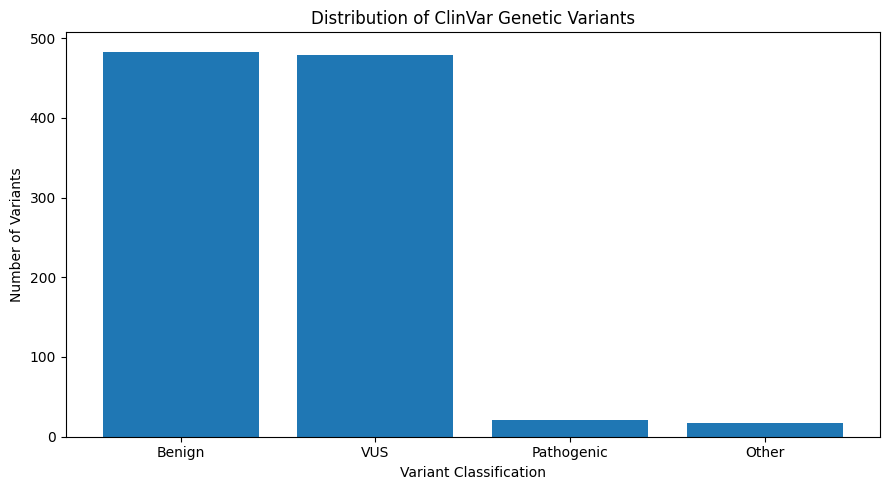

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    summary.index,
    summary["Count"]
)

plt.title("Distribution of ClinVar Genetic Variants")
plt.xlabel("Variant Classification")
plt.ylabel("Number of Variants")

plt.tight_layout()
plt.savefig("ClinVar_Variant_Distribution.png", dpi=300)
plt.show()

In [10]:
print(df[["Variant_ID", "Clinical_Significance", "Review_Status"]].head(10))

  Variant_ID   Clinical_Significance                        Review_Status
0    3385321  Uncertain_significance  criteria_provided,_single_submitter
1    2205837           Likely_benign  criteria_provided,_single_submitter
2    4562067  Uncertain_significance  criteria_provided,_single_submitter
3    3925305  Uncertain_significance  criteria_provided,_single_submitter
4    3205580  Uncertain_significance  criteria_provided,_single_submitter
5    3925306  Uncertain_significance  criteria_provided,_single_submitter
6    4832091  Uncertain_significance  criteria_provided,_single_submitter
7    3205581  Uncertain_significance  criteria_provided,_single_submitter
8    4127217  Uncertain_significance  criteria_provided,_single_submitter
9    2252161  Uncertain_significance  criteria_provided,_single_submitter


In [11]:
def review_priority(status):

    status = str(status).lower()

    if "practice_guideline" in status:
        return "High"

    elif "reviewed_by_expert_panel" in status:
        return "High"

    elif "multiple_submitters" in status and "no_conflicts" in status:
        return "High"

    elif "single_submitter" in status:
        return "Moderate"

    else:
        return "Low/Unclear"


df["Review_Priority"] = df["Review_Status"].apply(review_priority)

print(df[["Variant_ID", "Clinical_Significance", "Review_Priority"]].head(10))

  Variant_ID   Clinical_Significance Review_Priority
0    3385321  Uncertain_significance        Moderate
1    2205837           Likely_benign        Moderate
2    4562067  Uncertain_significance        Moderate
3    3925305  Uncertain_significance        Moderate
4    3205580  Uncertain_significance        Moderate
5    3925306  Uncertain_significance        Moderate
6    4832091  Uncertain_significance        Moderate
7    3205581  Uncertain_significance        Moderate
8    4127217  Uncertain_significance        Moderate
9    2252161  Uncertain_significance        Moderate


In [12]:
final_report = df[[
    "Chromosome",
    "Position",
    "Variant_ID",
    "Reference",
    "Alternate",
    "Clinical_Significance",
    "Disease",
    "Variant_Category",
    "Review_Status",
    "Review_Priority"
]]

final_report.head(10)

,Chromosome,Position,Variant_ID,Reference,Alternate,Clinical_Significance,Disease,Variant_Category,Review_Status,Review_Priority
0,1,66926,3385321,AG,A,Uncertain_significance,Retinitis_pigmentosa,VUS,"criteria_provided,_single_submitter",Moderate
1,1,69134,2205837,A,G,Likely_benign,not_specified,Benign,"criteria_provided,_single_submitter",Moderate
2,1,69241,4562067,C,T,Uncertain_significance,not_specified,VUS,"criteria_provided,_single_submitter",Moderate
3,1,69308,3925305,A,G,Uncertain_significance,not_specified,VUS,"criteria_provided,_single_submitter",Moderate
4,1,69314,3205580,T,G,Uncertain_significance,not_specified,VUS,"criteria_provided,_single_submitter",Moderate
5,1,69404,3925306,T,C,Uncertain_significance,not_specified,VUS,"criteria_provided,_single_submitter",Moderate
6,1,69416,4832091,T,C,Uncertain_significance,not_specified,VUS,"criteria_provided,_single_submitter",Moderate
7,1,69423,3205581,G,A,Uncertain_significance,not_specified,VUS,"criteria_provided,_single_submitter",Moderate
8,1,69506,4127217,C,G,Uncertain_significance,not_specified,VUS,"criteria_provided,_single_submitter",Moderate
9,1,69581,2252161,C,G,Uncertain_significance,not_specified,VUS,"criteria_provided,_single_submitter",Moderate


In [14]:
final_report.to_csv("ClinVar_Variant_Annotation_Report.csv", index=False)

In [15]:
from google.colab import files

files.download("ClinVar_Variant_Annotation_Report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
from google.colab import files

files.download("ClinVar_Variant_Distribution.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>